# Week 10 - Clustering 1, K-Means
## Dataset: NOAA Storm Events

This week moves from supervised learning to clustering, starting with k-means. Every model so far learned to predict a label, such as whether an event reported damage. Clustering has no label. It looks for groups of events that sit close together in feature space, and the analyst has to decide whether those groups mean anything.

K-means places k cluster centers, assigns each event to its nearest center, moves each center to the mean of its events, and repeats until nothing changes. It minimizes inertia, the sum of squared Euclidean distances from each event to its center. Because everything depends on distance, the choices that matter most are which features go in, how they are scaled, and how distance is measured. The number of clusters k also has to be chosen, here with the elbow method and the silhouette score.

The question for Storm Events is whether 2017 events fall into distinct storm regimes by place, season, and duration, and whether those regimes differ in how often damage is reported. Event type and damage are left out of the clustering so they can be used afterward to check what the clusters mean.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Data and features

The events are the same 31,863 used in Weeks 4 to 9, those with a location and a damage entry. Two features are rebuilt for distance. The day of the year is placed on a circle with a sine and a cosine, so that December 31 and January 1 are neighbors. Latitude and longitude are converted to kilometers east and north, since a degree of longitude is about 99 km at 27 degrees north but only about 74 km at 48 degrees north.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['logDuration'] = np.log10(data['durationHours'] + 0.1)
data['month'] = begin.dt.month
data['dayOfYear'] = begin.dt.dayofyear
data = data.dropna(subset=['month', 'logDuration']).reset_index(drop=True)

# Season on a circle, so December 31 sits next to January 1
angle = 2 * np.pi * data['dayOfYear'] / 365.25
data['seasonSin'], data['seasonCos'] = np.sin(angle), np.cos(angle)
# Location in kilometers, so a kilometer east counts the same as a kilometer north
data['eastKm'] = data['BEGIN_LON'] * 111.32 * np.cos(np.radians(data['BEGIN_LAT']))
data['northKm'] = data['BEGIN_LAT'] * 110.57
print('Events used:', len(data), '| share with damage reported:', round(data['damaged'].mean(), 3))
print(data['EVENT_TYPE'].value_counts().head(8).to_string())

Events used: 31863 | share with damage reported: 0.347
EVENT_TYPE
Thunderstorm Wind           12954
Hail                         7707
Flash Flood                  3662
Flood                        2472
Tornado                      1407
Marine Thunderstorm Wind     1363
Heavy Rain                   1250
Lightning                     354


### Feature scaling and how distance is measured

The next cell clusters the events with k = 6 under three feature designs and reports which feature the clusters split on most, measured as the share of that feature's variance explained by the clusters. It also measures how far apart two events one day apart across New Year are under each way of coding the season.

In [3]:
designs = {'Raw: latitude, longitude, month, log duration': (['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration'], False),
           'Standardized: same four features': (['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration'], True),
           'Standardized: km east, km north, season on a circle, log duration':
               (['eastKm', 'northKm', 'seasonSin', 'seasonCos', 'logDuration'], True)}
design_rows, design_Z = [], {}
for name, (cols, scale) in designs.items():
    Z = StandardScaler().fit_transform(data[cols]) if scale else data[cols].values
    design_Z[name] = Z
    labels = KMeans(n_clusters=6, n_init=10, random_state=0).fit_predict(Z)
    explained = pd.Series({c: 1 - pd.Series(Z[:, i]).groupby(labels).var().mul(np.bincount(labels)).sum()
                           / (Z[:, i].var() * len(Z)) for i, c in enumerate(cols)})
    design_rows.append({'Feature design (k = 6)': name, 'Feature the clusters split on most': explained.idxmax(),
                        'Its variance explained': explained.max(), 'Least-used feature': explained.idxmin(),
                        'Its variance explained ': explained.min()})
print(pd.DataFrame(design_rows).round(3).to_string(index=False))

# Two events one day apart across New Year, measured in standardized units
sd_month = data['month'].std()
z_season = StandardScaler().fit(data[['seasonSin', 'seasonCos']].values)
dec31 = np.array([[np.sin(2 * np.pi * 365 / 365.25), np.cos(2 * np.pi * 365 / 365.25)]])
jan1 = np.array([[np.sin(2 * np.pi * 1 / 365.25), np.cos(2 * np.pi * 1 / 365.25)]])
jul1 = np.array([[np.sin(2 * np.pi * 182 / 365.25), np.cos(2 * np.pi * 182 / 365.25)]])
gap = lambda a, b: np.linalg.norm(z_season.transform(a) - z_season.transform(b))
print(f'\nStandardized distance from December 31 to January 1, month as a number: {11 / sd_month:.2f}'
      f' | season on a circle: {gap(dec31, jan1):.2f}')
print(f'Standardized distance from January 1 to July 1, month as a number: {6 / sd_month:.2f}'
      f' | season on a circle: {gap(jan1, jul1):.2f}')

                                           Feature design (k = 6) Feature the clusters split on most  Its variance explained Least-used feature  Its variance explained 
                    Raw: latitude, longitude, month, log duration                          BEGIN_LON                   0.885              month                    0.047
                                 Standardized: same four features                        logDuration                   0.713              month                    0.469
Standardized: km east, km north, season on a circle, log duration                        logDuration                   0.655            northKm                    0.429

Standardized distance from December 31 to January 1, month as a number: 4.82 | season on a circle: 0.03
Standardized distance from January 1 to July 1, month as a number: 2.63 | season on a circle: 3.30


Without scaling, k-means is a longitude clustering. Longitude has a standard deviation of about 11.7 degrees, far more than the month (2.3) or log duration (0.7), so the six clusters explain 88.5% of the variance in longitude and only 4.7% of the variance in the month. After standardizing, every feature shapes the clusters, from 71.3% of the variance in log duration down to 46.9% for the month. The final design explains between 42.9% (kilometers north) and 65.5% (log duration) of each feature's variance.

The month as a number has a problem that scaling cannot fix. December 31 and January 1 are a day apart, but their standardized distance is 4.82, almost twice the distance between January 1 and July 1 (2.63). On the circle the two New Year dates are 0.03 apart and January and July are 3.30 apart, which matches how far apart they are in the seasons.

### Choosing k

The next cell runs k-means for k from 2 to 12 on the final design and records the inertia, for the elbow method, and the silhouette score. The silhouette of an event compares its average distance to the other events in its own cluster (a) with its average distance to the events in the nearest other cluster (b), as (b - a) / max(a, b). It runs from -1 to 1, and values near 1 mean tight, well-separated clusters. Since it compares pairs of events, it is computed on a random 10,000. The elbow point is found as the k whose scaled inertia lies farthest below the straight line from k = 2 to k = 12.

 k    Inertia  Silhouette  Distance from the line
 2 124775.846       0.241                   0.000
 3 103539.944       0.251                   0.166
 4  88407.237       0.259                   0.256
 5  79021.922       0.245                   0.274
 6  71132.093       0.260                   0.273
 7  65218.460       0.250                   0.247
 8  60622.770       0.242                   0.205
 9  55453.785       0.266                   0.170
10  52125.654       0.250                   0.112
11  47844.787       0.264                   0.065
12  45072.200       0.260                   0.000
Elbow point: 5 | highest silhouette: 9


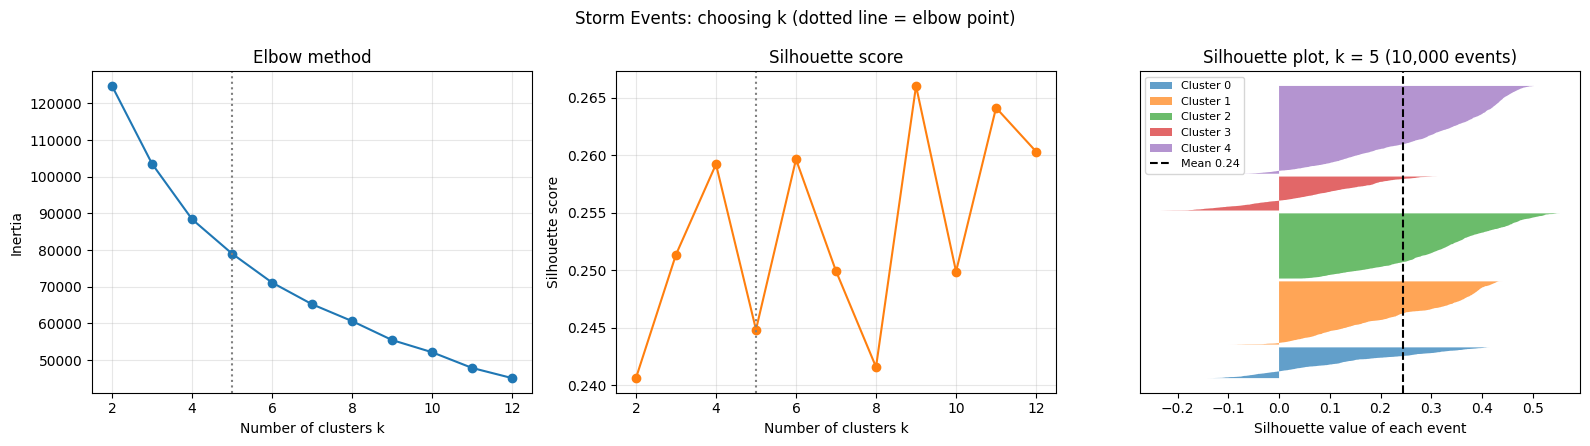

In [4]:
cols = ['eastKm', 'northKm', 'seasonSin', 'seasonCos', 'logDuration']
Z = design_Z['Standardized: km east, km north, season on a circle, log duration']
k_rows = []
for k in range(2, 13):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    k_rows.append({'k': k, 'Inertia': m.inertia_, 'Silhouette': silhouette_score(Z, m.labels_, sample_size=10000, random_state=0)})
k_table = pd.DataFrame(k_rows)
x = (k_table['k'] - 2) / 10
yv = (k_table['Inertia'] - k_table['Inertia'].min()) / (k_table['Inertia'].max() - k_table['Inertia'].min())
k_table['Distance from the line'] = (1 - x) - yv
k_best = int(k_table.loc[k_table['Distance from the line'].idxmax(), 'k'])
print(k_table.round(3).to_string(index=False))
print('Elbow point:', k_best, '| highest silhouette:', int(k_table.loc[k_table['Silhouette'].idxmax(), 'k']))

model = KMeans(n_clusters=k_best, n_init=10, random_state=0).fit(Z)
data['cluster'] = model.labels_
sample = np.random.RandomState(0).choice(len(data), 10000, replace=False)
sil = silhouette_samples(Z[sample], model.labels_[sample])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(k_table['k'], k_table['Inertia'], marker='o')
axes[0].set_title('Elbow method')
axes[0].set_ylabel('Inertia')
axes[1].plot(k_table['k'], k_table['Silhouette'], marker='o', color='C1')
axes[1].set_title('Silhouette score')
axes[1].set_ylabel('Silhouette score')
for ax in axes[:2]:
    ax.axvline(k_best, color='gray', linestyle=':')
    ax.set_xlabel('Number of clusters k')
    ax.grid(alpha=0.3)
y0 = 0
for c in range(k_best):
    vals = np.sort(sil[model.labels_[sample] == c])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, alpha=0.7, label=f'Cluster {c}')
    y0 += len(vals) + 100
axes[2].axvline(sil.mean(), color='black', linestyle='--', label=f'Mean {sil.mean():.2f}')
axes[2].set_xlabel('Silhouette value of each event')
axes[2].set_yticks([])
axes[2].set_title(f'Silhouette plot, k = {k_best} (10,000 events)')
axes[2].legend(fontsize=8)
fig.suptitle('Storm Events: choosing k (dotted line = elbow point)')
plt.tight_layout()
plt.show()

The inertia always falls as k grows, since more centers always fit better, so the question is where the gains level off. The curve bends gradually with no sharp elbow, and the line method places the elbow at k = 5. The silhouette is low for every k (0.24 to 0.27) and zigzags between neighboring values, with its highest point at k = 9. A silhouette near 0.25 means the average event is only a little closer to its own cluster than to the next one, so the events form a continuum that k-means divides into regions, not separate groups. The silhouette plot at k = 5 shows this. Most events have positive values, but clusters 0 and 3 contain many events with negative values, which sit closer to another cluster's events than to their own. I used k = 5, the elbow point, since no silhouette value stands out and the split-half check later in the notebook shows that k = 5 is reproducible.

### What the clusters mean

The next cell profiles each cluster by its location, peak month, median duration, most common event types, and damage share. Event type and damage were not used to form the clusters, so they test whether the clusters mean anything.

Cluster profiles (event type and damage were not used to form the clusters)
         events  latitude  longitude peakMonth  medianHours            topType  topTypeShare         secondType  damageShare  episodes
cluster                                                                                                                               
0          3494     39.19     -92.45       Apr         6.00              Flood          0.44        Flash Flood         0.31       940
1          7197     35.84     -91.75       Mar         0.00  Thunderstorm Wind          0.43               Hail         0.37       813
2          7474     34.56     -92.76       May         0.00  Thunderstorm Wind          0.48               Hail         0.32      1174
3          3748     32.41     -97.08       Aug         0.08        Flash Flood          0.31  Thunderstorm Wind         0.30      1072
4          9950     41.85     -86.79       Jul         0.00  Thunderstorm Wind          0.53               Hail   

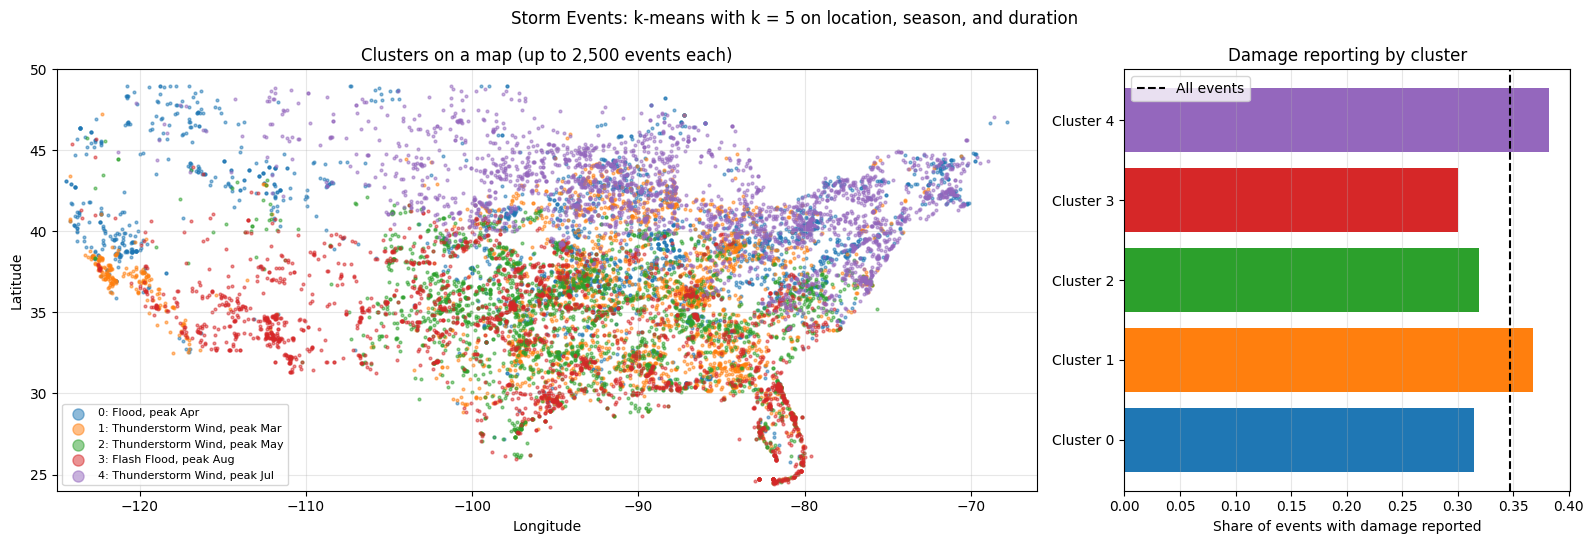

In [5]:
months = 'Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec'.split()
summary = data.groupby('cluster').agg(
    events=('damaged', 'size'), latitude=('BEGIN_LAT', 'mean'), longitude=('BEGIN_LON', 'mean'),
    peakMonth=('month', lambda s: months[int(s.mode().iloc[0]) - 1]), medianHours=('durationHours', 'median'),
    topType=('EVENT_TYPE', lambda s: s.value_counts().index[0]),
    topTypeShare=('EVENT_TYPE', lambda s: s.value_counts(normalize=True).iloc[0]),
    secondType=('EVENT_TYPE', lambda s: s.value_counts().index[1]),
    damageShare=('damaged', 'mean'), episodes=('EPISODE_ID', 'nunique'))
print('Cluster profiles (event type and damage were not used to form the clusters)')
print(summary.round(2).to_string())
print(f'\nOverall damage share: {data["damaged"].mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
for c in range(k_best):
    pts = data[data['cluster'] == c].sample(min(2500, (data['cluster'] == c).sum()), random_state=0)
    axes[0].scatter(pts['BEGIN_LON'], pts['BEGIN_LAT'], s=4, alpha=0.5,
                    label=f'{c}: {summary.loc[c, "topType"]}, peak {summary.loc[c, "peakMonth"]}')
axes[0].set_xlim(-125, -66)
axes[0].set_ylim(24, 50)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Clusters on a map (up to 2,500 events each)')
axes[0].legend(fontsize=8, markerscale=4, loc='lower left')
axes[0].grid(alpha=0.3)
axes[1].barh([f'Cluster {c}' for c in summary.index], summary['damageShare'], color=[f'C{c}' for c in summary.index])
axes[1].axvline(data['damaged'].mean(), color='black', linestyle='--', label='All events')
axes[1].set_xlabel('Share of events with damage reported')
axes[1].set_title('Damage reporting by cluster')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='x')
fig.suptitle(f'Storm Events: k-means with k = {k_best} on location, season, and duration')
plt.tight_layout()
plt.show()

The five clusters are recognizable storm regimes.

- **Cluster 4** (9,950 events) is summer severe weather in the northern half of the country, centered near 42 degrees north with a July peak, mostly thunderstorm wind and hail.
- **Clusters 1 and 2** (7,197 and 7,474 events) are spring severe weather in the South, one peaking in March and the other in May.
- **Cluster 0** (3,494 events) is long-lasting flooding, with a median duration of 6 hours, mostly river floods (44%) and flash floods peaking in April, and it also takes in many of the West Coast's winter floods.
- **Cluster 3** (3,748 events) is the late-summer Southwest and Gulf, with an August peak, led by flash floods (31%) from the monsoon and the hurricane season, including Irma's events in Florida.

Damage reporting barely differs between them. The damage share runs from 0.30 to 0.38 against 0.347 overall, so the regimes describe when and where storms happen far better than whether they cause reported damage. That fits earlier weeks, where the event type and the reporting office mattered more than the season.

### Distance metrics

K-means always minimizes squared Euclidean distance, but the clusters can be judged under other metrics. The next cell scores the same clusters with Manhattan and cosine silhouettes, and refits k-means on standardized degrees instead of kilometers to see how much the location metric changes the result.

In [6]:
metric_rows = [{'Silhouette computed with': m,
                'Score (same k-means clusters)': silhouette_score(Z, model.labels_, metric=m, sample_size=10000, random_state=0)}
               for m in ['euclidean', 'manhattan', 'cosine']]
print(pd.DataFrame(metric_rows).round(3).to_string(index=False))

# Does a better distance for location (kilometers instead of degrees) change the clusters?
Z_deg = StandardScaler().fit_transform(data[['BEGIN_LON', 'BEGIN_LAT', 'seasonSin', 'seasonCos', 'logDuration']])
deg_labels = KMeans(n_clusters=k_best, n_init=10, random_state=0).fit_predict(Z_deg)
print(f'\nARI between clusters on kilometers and on raw degrees (both standardized): '
      f'{adjusted_rand_score(model.labels_, deg_labels):.3f}')

Silhouette computed with  Score (same k-means clusters)
               euclidean                          0.245
               manhattan                          0.235
                  cosine                          0.416



ARI between clusters on kilometers and on raw degrees (both standardized): 0.372


The silhouette is 0.245 with Euclidean distance, 0.235 with Manhattan distance, and 0.416 with cosine distance. Cosine distance only compares directions from the center of the standardized data, and k-means clusters in standardized data tend to sit like slices around that center, so they look better separated by angle than by distance. A higher silhouette under a different metric is not evidence of better clusters, only of a different idea of similarity, which is why the metric has to be chosen before the clusters are judged. Measuring location in degrees instead of kilometers changes most of the partition (ARI 0.372 between the two), since a degree of longitude stands for a different distance at each latitude.

### Stability

A clustering that changes completely when the data or the random start changes cannot be trusted. The next cell compares 10 runs with a single random start each. It then clusters two halves of the data, each made of whole storm episodes, and checks whether the half-A centers label half B the same way half B's own clustering does.

In [7]:
runs = [KMeans(n_clusters=k_best, n_init=1, random_state=s).fit(Z) for s in range(10)]
seed_ari = [adjusted_rand_score(runs[i].labels_, runs[j].labels_) for i in range(10) for j in range(i + 1, 10)]
inertias = [r.inertia_ for r in runs]
print(f'ARI between 10 single-start runs: min {min(seed_ari):.3f}, median {np.median(seed_ari):.3f}')
print(f'Inertia spread across starts: {(max(inertias) - min(inertias)) / min(inertias):.3f}')

# Split-half check by storm episode, so each half contains whole storms
episodes = data['EPISODE_ID'].unique()
half_eps = set(np.random.RandomState(1).choice(episodes, len(episodes) // 2, replace=False))
half = data['EPISODE_ID'].isin(half_eps).values
model_a = KMeans(n_clusters=k_best, n_init=10, random_state=0).fit(Z[half])
model_b = KMeans(n_clusters=k_best, n_init=10, random_state=0).fit(Z[~half])
print(f'Split-half ARI (halves made of whole episodes): {adjusted_rand_score(model_a.predict(Z[~half]), model_b.labels_):.3f}')
for k in [3, 6, 9]:
    a = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z[half])
    b = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z[~half])
    print(f'  k = {k}: split-half ARI {adjusted_rand_score(a.predict(Z[~half]), b.labels_):.3f}')

ARI between 10 single-start runs: min 0.444, median 0.618
Inertia spread across starts: 0.016
Split-half ARI (halves made of whole episodes): 0.811


  k = 3: split-half ARI 0.675
  k = 6: split-half ARI 0.903


  k = 9: split-half ARI 0.481


With a single random start, two runs agree with an ARI as low as 0.444 (median 0.618), and their inertia differs by up to 1.6%, so many different partitions fit almost equally well. That is another sign of weak cluster structure, and it is why every fit here uses 10 starts (`n_init=10`) and keeps the best. With 10 starts the halves agree well, with a split-half ARI of 0.811 at k = 5. The check also helps with k. Agreement is 0.675 at k = 3, 0.903 at k = 6, and 0.481 at k = 9, so the silhouette's favorite, k = 9, is the least reproducible.

## Discussion

### Overfitting

Clustering has no labels, so overfitting shows up as clusters that describe noise in this sample instead of structure that would appear again. Three checks guarded against it. The number of clusters was chosen with the elbow method and the silhouette score, which stop rewarding extra centers once they no longer separate the data. Every fit used 10 random starts, because a single start landed on visibly different partitions. And the split-half check, with halves made of whole storm episodes so one storm could not appear in both, showed the k = 5 clusters reappearing with an ARI of 0.811, while k = 9 dropped to 0.481. That last result is the clearest evidence of overfitting in this notebook. Nine clusters had the best silhouette, but they did not survive a change of sample.

### Metrics and hyperparameter tuning

The metrics were inertia (the within-cluster sum of squared distances, used for the elbow method), the silhouette score (how much closer each event is to its own cluster than to the next, from -1 to 1), and the adjusted Rand index (ARI, the agreement between two partitions after correcting for chance, where 0 is chance and 1 is identical). The main hyperparameter is k, the number of clusters, chosen at 5. The other choices act like hyperparameters, namely the features, their scaling, the season encoding, the kilometer projection, and the number of random starts. Standardization and the season circle had the largest effect, since they decided which features the clusters could follow at all.

### Expected or unexpected

I expected k-means to find regional storm seasons, and it did. I did not expect the clusters to be so weakly separated, with a silhouette near 0.25 at every k, or to explain so little of the damage reports (0.30 to 0.38 against 0.347 overall). Storm events form a continuum across space and the calendar. The cosine silhouette (0.416) was also a surprise and a useful warning that a score depends on the metric used to compute it. The size of the New Year problem was unexpected as well, since coding the month as a number put December 31 farther from January 1 than from July.

### How EDA helped

The Module B EDA showed that event duration is extremely right-skewed, so duration enters as a log, without which a few multi-day floods would dominate every distance. The Week 4 finding that outlying events in Alaska and American Samoa stretch the coordinate ranges is why min-max scaling was not used, and the episode structure found in Week 4 is why the split-half check keeps whole episodes together. EDA did not reveal that the events lack natural groups. That only became clear from the silhouette scores.

### External sources

- Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms*, 1027-1035.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65.
- scikit-learn example, "Selecting the number of clusters with silhouette analysis on KMeans clustering": https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
- scikit-learn User Guide, "Clustering," the sections on k-means and on clustering performance evaluation: https://scikit-learn.org/stable/modules/clustering.html

### Conclusions

K-means divides 2017 storm events into five regional and seasonal regimes, summer storms in the North, two waves of spring storms in the South, long-lasting floods, and late-summer flash floods in the Southwest and Gulf. The regimes are reproducible across halves of the data (ARI 0.811), but they are weakly separated (silhouette 0.245), and their damage shares stay close to the overall rate. The choices that mattered most were standardizing, which stopped longitude from deciding everything, and placing the season on a circle.

For Milestone Two and the Capstone, the clusters are more useful as a description of when and where storms occur than as a predictor of damage, which is consistent with Weeks 4 to 9, where event type, location, and reporting office carried most of the signal. Clustering whole storm systems instead of single events is a natural next step, and Week 11's DBSCAN takes it.